In [1]:
import math

import galsim
import matplotlib.pyplot as pyplot
import numpy
import plotly.graph_objects as go
from functions_images import build_full_image, build_psf, get_constants, get_offset, unpack_lhs
from functions_lhs import adding_cosmos_catalog_galaxies, draw_lhs_gal, draw_lhs_img
from functions_projections import project_lhs
from tqdm import tqdm
from utils import DIRS

In [3]:
NB_OF_SAMPLES = 3
ELLIPS_STYLE = "gaussian"
PIXELS_OUT = False
LHS_POS = False
SEED_DATABASE = 2222
PERCENTAGE_COSMOS = 50
TYPE_COSMOS = "real"  # "real" or "parametric"

GSPARAMS = galsim.GSParams(
    xvalue_accuracy=2.0e-4, kvalue_accuracy=2.0e-4, maxk_threshold=5.0e-3, folding_threshold=1.0e-2
)
PIXEL_SCALE, XSIZE, YSIZE, IMG_SIZE, EXPTIME, GAIN, readoutnoise, SKY_BKG, ZP = get_constants()

In [4]:
# create lhs image
lhs_img = draw_lhs_img(seed=SEED_DATABASE * 1_000, n_samples=NB_OF_SAMPLES)

# create lhs galaxies
lhs_gal = draw_lhs_gal(LHS_POS, SEED_DATABASE, NB_OF_SAMPLES * 10)

# lhs galaxies projection
lhs_gal = project_lhs(hypercube=lhs_gal, ellips_style=ELLIPS_STYLE, pixel_out=PIXELS_OUT)

# taking real/parametric galaxies from cosmos catalogs
nb_galaxies_cosmos = int(PERCENTAGE_COSMOS * NB_OF_SAMPLES * 10 / 100)

numpy.random.seed(22)
replace_indices = numpy.random.choice(a=NB_OF_SAMPLES * 10, size=nb_galaxies_cosmos, replace=False)

lhs_gal = adding_cosmos_catalog_galaxies(lhs_gal, numpy.sort(replace_indices))

psf = build_psf("airy")

In [35]:
stamps = []
for i in tqdm(range(lhs_img.shape[0]), desc="Rendering galaxy scenes"):
    # sigma_noise = []
    img_params = lhs_img[i]
    gal_params = lhs_gal[i * 10 : (i + 1) * 10]

    params = unpack_lhs([img_params, gal_params])
    avg_g1 = params["g1"]
    avg_g2 = params["g2"]

    full_image = build_full_image(IMG_SIZE, PIXEL_SCALE)
    noise_image = build_full_image(IMG_SIZE, PIXEL_SCALE)
    flux = EXPTIME / GAIN * 10 ** (-(params["mag"] - ZP) / 2.5)

    for i in range(10):
        # compute Sersic profile with cosmos
        if params["index_cosmos"][i] > 0:
            CHOICE = int(params["index_cosmos"][i])
            SAMPLE = str(params["sample_cosmos"][i])

            cosmos_cat = galsim.COSMOSCatalog(
                sample=SAMPLE,
                dir=DIRS["cosmos"],
                use_real=True,
                exclusion_level="none",
                exptime=EXPTIME,
            )

            # gal = cosmos_cat.makeGalaxy(
            #     gal_type=TYPE_COSMOS,
            #     index=CHOICE,
            #     deep=False,
            #     noise_pad_size=0,
            #     sersic_prec=0.0,
            #     gsparams=GSPARAMS,
            # )

            # _, _, galaxy_variance = cosmos_cat.real_cat.getNoiseProperties(CHOICE)
            gal_image, *_ = cosmos_cat.getRealParams(CHOICE)
            gal = galsim.InterpolatedImage(
                gal_image, scale=PIXEL_SCALE, normalization="flux", gsparams=GSPARAMS
            )
            BRIGHTNESS_BOOST = 3
            gal = gal.withFlux(flux[i] * BRIGHTNESS_BOOST)

        else:
            # compute Sersic profile with galsim
            gal = galsim.Sersic(
                n=params["sersic"][i],
                half_light_radius=params["hlr"][i],
                flux=flux[i],
                gsparams=GSPARAMS,
                trunc=params["hlr"][i] * 4.5,
            )

        # apply ellips
        gal = gal.shear(e1=params["int_e1"][i], e2=params["int_e2"][i])

        # apply shear
        gal = gal.shear(g1=avg_g1, g2=avg_g2)  # simple case

        # convolve galaxy with PSF
        final = galsim.Convolve([psf, gal])

        # offset
        image_pos, ix_nominal, iy_nominal, offset = get_offset(
            params["off_x"][i], params["off_y"][i], params["x"][i], params["y"][i]
        )

        # draw galaxy
        stamp = galsim.ImageF(IMG_SIZE, IMG_SIZE, scale=PIXEL_SCALE)
        final.drawImage(image=stamp, wcs=full_image.wcs.local(image_pos), offset=offset)
        stamp.setCenter(ix_nominal, iy_nominal)

        # add stamp to the main image
        bounds = stamp.bounds & full_image.bounds
        full_image[bounds] += stamp[bounds]

    # gaussian noise image
    F_SKY = PIXEL_SCALE ** (2) * EXPTIME * 10 ** (-(SKY_BKG - ZP) / 2.5)  # e-/pixel
    variance = (numpy.sqrt(readoutnoise**2 + F_SKY) / GAIN) ** 2  # e- -> ADU
    noise = galsim.GaussianNoise(rng=galsim.BaseDeviate(22), sigma=numpy.sqrt(variance))
    noise_image.addNoise(noise)

    # # add noise
    # full_image += noise_image
    full_image_array = full_image.array
    stamps.append(full_image_array)

Rendering galaxy scenes:   0%|          | 0/3 [00:00<?, ?it/s]

Rendering galaxy scenes: 100%|██████████| 3/3 [00:13<00:00,  4.39s/it]


In [36]:
# name = "parametric_no_noise"
# name = "parametric_noise"
# name = "real_no_noise"
# name = "real_noise"
name = "real_noise_0"

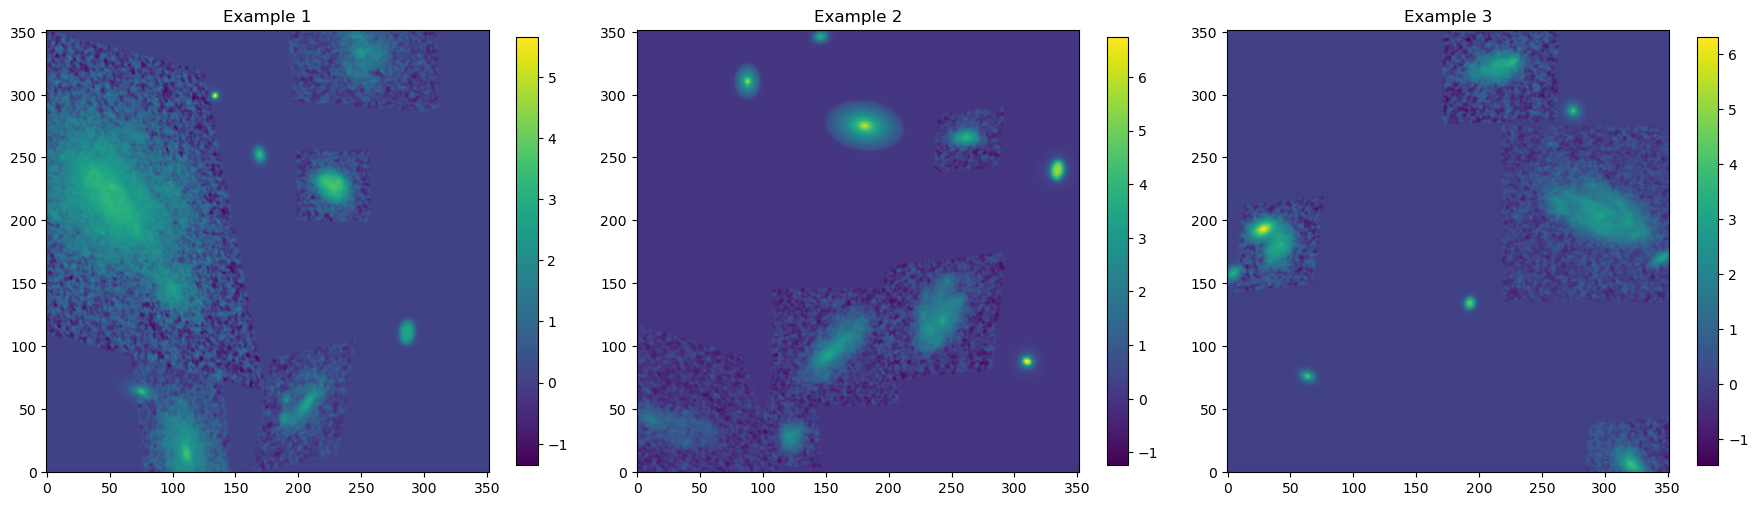

In [37]:
fig, axes = pyplot.subplots(1, 3, figsize=(18, 6))
for idx, ax in enumerate(axes.flat):
    im = ax.imshow(numpy.arcsinh(stamps[idx]), origin="lower")
    # im = ax.imshow((stamps[idx]), origin="lower")
    ax.set_title(f"Example {idx + 1}")
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
fig.savefig(DIRS["images_cosmos"] / f"{name}.pdf", dpi=300, bbox_inches="tight")
fig.show()

In [ ]:
fig, axes = pyplot.subplots(1, 3, figsize=(18, 6))
for idx, ax in enumerate(axes.flat):
    im = ax.imshow(numpy.arcsinh(stamps[idx]), origin="lower")
    ax.set_title(f"Example {idx + 1}")
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
fig.show()

In [ ]:
cosmos_cat = galsim.COSMOSCatalog(
    sample=SAMPLE,
    dir=DIRS["cosmos"],
    use_real=True,
    exclusion_level="none",
    exptime=EXPTIME,
)

gal = cosmos_cat.makeGalaxy(
    gal_type=TYPE_COSMOS,
    index=CHOICE,
    deep=False,
    noise_pad_size=0,
    sersic_prec=0.0,
    gsparams=GSPARAMS,
)

common_kwargs = dict(index=CHOICE, noise_pad_size=0, deep=False, sersic_prec=0.0, gsparams=GSPARAMS)

real_gal = cosmos_cat.makeGalaxy(gal_type="real", **common_kwargs)
param_gal = cosmos_cat.makeGalaxy(gal_type="parametric", **common_kwargs)


In [ ]:
_, _, galaxy_variance = cosmos_cat.real_cat.getNoiseProperties(CHOICE)
gal_image, psf_image, noise_image, _, _ = cosmos_cat.getRealParams(CHOICE)
sigma_noise = numpy.sqrt(galaxy_variance)

In [ ]:
pyplot.figure(figsize=(6, 6))
pyplot.imshow(gal_image.array, origin="lower")
pyplot.colorbar(label="Flux")
pyplot.tight_layout()
pyplot.show()

In [ ]:
cosmos_cat = galsim.COSMOSCatalog(
    sample=SAMPLE, dir=DIRS["cosmos"], use_real=USE_REAL, exclusion_level="none", exptime=EXPTIME
)
common_kwargs = dict(index=CHOICE, noise_pad_size=0, deep=False, sersic_prec=0.0, gsparams=gsparams)

real_gal = cosmos_cat.makeGalaxy(gal_type="real", **common_kwargs)
param_gal = cosmos_cat.makeGalaxy(gal_type="parametric", **common_kwargs)
psf = build_psf("airy")

real_gal = galsim.Convolve(real_gal, psf)
im_real = galsim.Image(IM_SIZE, IM_SIZE)
real_gal.drawImage(image=im_real, scale=PIXEL_SCALE)

param_gal = galsim.Convolve(param_gal, psf)
im_param = galsim.Image(IM_SIZE, IM_SIZE)
param_gal.drawImage(image=im_param, scale=PIXEL_SCALE)

fig, axs = pyplot.subplots(1, 2, figsize=(8, 4))

im0 = axs[0].imshow(im_real.array, origin="lower")
axs[0].set_title(f"Real Galaxy {CHOICE}")
fig.colorbar(im0, ax=axs[0], orientation="vertical", fraction=0.05, pad=0.05)
im1 = axs[1].imshow(im_param.array, origin="lower")
axs[1].set_title(f"Parametric Model {CHOICE}")
fig.colorbar(im1, ax=axs[1], orientation="vertical", fraction=0.05, pad=0.05)

fig.tight_layout()
fig.show()

In [ ]:
fig, axes = pyplot.subplots(1, 3, figsize=(18, 6))
for idx, ax in enumerate(axes.flat):
    im = ax.imshow(numpy.arcsinh(stamps[idx]), origin="lower")
    ax.set_title(f"Example {idx + 1}")
    fig.colorbar(im, ax=ax, shrink=0.75)
fig.tight_layout()
fig.show()

In [ ]:
# def comparaison_3d(catalog_features, test_points, results, with_catalog=False):
#     width = 1200
#     height = 1200

#     fig = go.Figure()

#     if with_catalog:
#         fig.add_trace(
#             go.Scatter3d(
#                 x=catalog_features[:, 0],
#                 y=catalog_features[:, 1],
#                 z=catalog_features[:, 2],
#                 mode="markers",
#                 marker=dict(size=1, color="lightgray", opacity=0.2),
#                 name="Catalog",
#             )
#         )

#     text = [f"{i + 1}" for i in range(len(test_points))]
#     fig.add_trace(
#         go.Scatter3d(
#             x=test_points[:, 0],
#             y=test_points[:, 1],
#             z=test_points[:, 2],
#             mode="markers+text",
#             marker=dict(size=3, color="red"),
#             text=text,
#             name="Test points",
#         )
#     )

#     colors = {
#         ("min_max", "euclid"): "blue",
#         ("min_max", "mahalanobis"): "green",
#         ("z_score", "euclid"): "orange",
#         ("z_score", "mahalanobis"): "purple",
#     }

#     for (SCALING, NORMA), matched in results.items():
#         name = f"{SCALING.upper()} + {NORMA.title()}"
#         fig.add_trace(
#             go.Scatter3d(
#                 x=matched[:, 0],
#                 y=matched[:, 1],
#                 z=matched[:, 2],
#                 mode="markers",
#                 marker=dict(size=4, color=colors[(SCALING, NORMA)]),
#                 name=name,
#             )
#         )

#     scene = dict(xaxis_title="mag_auto", yaxis_title="hlr", zaxis_title="sersic")
#     fig.update_layout(scene=scene, width=width, height=height, showlegend=True)
#     fig.show()


In [ ]:
# results_features = {}
# results_selection = {}
# for SCALING in ["min_max", "z_score"]:
#     for NORMA in ["euclid", "mahalanobis"]:
#         catalog_features_norm, test_points_norm = normalise(
#             catalog_features, changing_samples, scaling=SCALING
#         )

#         diff = test_points_norm[:, numpy.newaxis, :] - catalog_features_norm[numpy.newaxis, :, :]

#         if NORMA == "euclid":
#             matched_idx = euclidian_style(diff)
#         elif NORMA == "mahalanobis":
#             matched_idx = maha_style(catalog_features_norm, diff)

#         matched_selection = catalog_selection[matched_idx]
#         matched_features = catalog_features[matched_idx]

#         results_features[(SCALING, NORMA)] = matched_features
#         results_selection[(SCALING, NORMA)] = matched_selection

# comparaison_3d(catalog_features, changing_samples, results_features, with_catalog=False)

In [ ]:
# cosmos_cat = galsim.COSMOSCatalog(
#     sample=SAMPLE, dir=DIRS["cosmos"], use_real=USE_REAL, exclusion_level="none", exptime=EXPTIME
# )
# common_kwargs = dict(
#     index=CHOICE, noise_pad_size=noise_pad_size, deep=False, sersic_prec=0.0, gsparams=gsparams
# )

# real_gal = cosmos_cat.makeGalaxy(gal_type="real", **common_kwargs)
# param_gal = cosmos_cat.makeGalaxy(gal_type="parametric", **common_kwargs)
# psf = build_psf("airy")

# real_gal = galsim.Convolve(real_gal, psf)
# im_real = galsim.Image(IM_SIZE, IM_SIZE)
# real_gal.drawImage(image=im_real, scale=PIXEL_SCALE)

# param_gal = galsim.Convolve(param_gal, psf)
# im_param = galsim.Image(IM_SIZE, IM_SIZE)
# param_gal.drawImage(image=im_param, scale=PIXEL_SCALE)

# fig, axs = pyplot.subplots(1, 2, figsize=(8, 4))

# im0 = axs[0].imshow(im_real.array, origin="lower")
# axs[0].set_title(f"Real Galaxy {CHOICE}")
# fig.colorbar(im0, ax=axs[0], orientation="vertical", fraction=0.05, pad=0.05)
# im1 = axs[1].imshow(im_param.array, origin="lower")
# axs[1].set_title(f"Parametric Model {CHOICE}")
# fig.colorbar(im1, ax=axs[1], orientation="vertical", fraction=0.05, pad=0.05)

# fig.tight_layout()
# fig.show()